In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 

In [9]:
df = pd.read_csv('../data/insurance.csv')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [11]:
df.describe([0.1,0.25,0.5,0.75,0.9])

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
10%,19.000000,22.990000,0.000000,2346.533615
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
90%,59.000000,38.619500,3.000000,34831.719700
max,64.000000,53.130000,5.000000,63770.428010


<Axes: xlabel='age', ylabel='charges'>

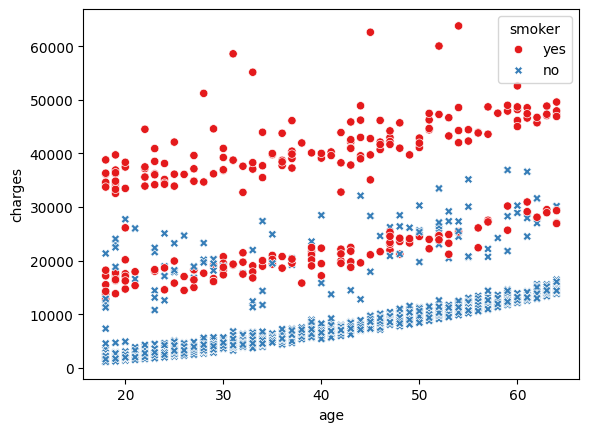

In [13]:
sns.scatterplot(x='age', y='charges', data=df, hue='smoker', style='smoker', palette='Set1')

In [14]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [17]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
X = df.drop(['charges','region'], axis=1)
y = df['charges']

In [21]:
X.head()

,age,sex,bmi,children,smoker
0,19,female,27.900,0,yes
1,18,male,33.770,1,no
2,28,male,33.000,3,no
3,33,male,22.705,0,no
4,32,male,28.880,0,no


In [22]:
#Feature Engineering
X['sex'] = X['sex'].map({'male':0, 'female':1})
X['smoker'] = X['smoker'].map({'no':0, 'yes':1})

In [23]:
X.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
dtype: object

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [25]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
y_pred = model.predict(X_test)

In [27]:
print(model.coef_)
print(model.intercept_)

[  260.03578967   -66.06974502   327.55999306   434.80431165
 23628.2381829 ]
-12234.710618819903


In [30]:
X_test.head()

,age,sex,bmi,children,smoker
764,45,1,25.175,2,0
887,36,1,30.020,0,0
890,64,1,26.885,0,1
1293,46,0,25.745,3,0
259,19,0,31.920,0,1


In [31]:
X_test.shape

(335, 5)

In [32]:
X_test['ped'] = y_pred

In [39]:
X_test.head()

,age,sex,bmi,children,smoker,ped,actual,ped_man
764,45,1,25.175,2,0,8516.761620,9095.06825,8516.761620
887,36,1,30.020,0,0,6893.859056,5272.17580,6893.859056
890,64,1,26.885,0,1,36776.198772,29330.98315,36776.198772
1293,46,0,25.745,3,0,9464.380662,9301.89355,9464.380662
259,19,0,31.920,0,1,26789.922546,33750.29180,26789.922546


In [34]:
X_test['actual'] = y_test

In [38]:
X_test['ped_man' ] = model.coef_[0]*X['age'] + model.coef_[1]*X['sex'] + model.coef_[2]*X['bmi'] + model.coef_[3]*X['children'] + model.coef_[4]*X['smoker'] + model.intercept_